In [54]:
#Import librairies
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import math 
from scipy.stats import pearsonr
import scipy.stats as stats
from plotly.subplots import make_subplots
from scipy.stats import shapiro
from sklearn.preprocessing import LabelEncoder,OneHotEncoder
from sklearn import preprocessing
from sklearn.feature_selection import RFE
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
import warnings
warnings.filterwarnings("ignore") 
from sklearn.preprocessing import LabelEncoder,OneHotEncoder
from sklearn import preprocessing
import plotly.graph_objects as go
import plotly.express as px
import missingno as msno
from statsmodels.stats.outliers_influence import variance_inflation_factor
from scipy.stats import skew, shapiro
from scipy.stats import boxcox
from sklearn.preprocessing import PowerTransformer
from sklearn.preprocessing import StandardScaler
import itertools
from sklearn.feature_selection import mutual_info_regression
from sklearn.ensemble import RandomForestRegressor
import shap
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import MinMaxScaler
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import EditedNearestNeighbours
from collections import Counter
from sklearn.feature_selection import SelectKBest
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from prettytable import PrettyTable
import featuretools as ft
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import lightgbm as lgb

## Probabilistic CLV model using BG/NBD (Beta-Geometric / Negative Binomial Distribution)

In [55]:
data = pd.read_csv(
    'C:/Users/Mega-Pc/Freelance/data/ecommerce/data_cleaned_orig.csv',encoding='ISO-8859-1')

In [56]:
from lifetimes.utils import summary_data_from_transaction_data

clv_summary = summary_data_from_transaction_data(
    transactions=data,
    customer_id_col='CustomerID',
    datetime_col='InvoiceDate',
    monetary_value_col='TotalPrice',
    observation_period_end=data['InvoiceDate'].max()
)

clv_summary.head()


,frequency,recency,T,monetary_value
CustomerID,,,,
12346.0,0.0,0.0,325.0,0.000000
12347.0,6.0,365.0,367.0,529.208333
12348.0,3.0,283.0,358.0,86.656667
12349.0,0.0,0.0,18.0,0.000000
12350.0,0.0,0.0,310.0,0.000000


In [57]:
from lifetimes import BetaGeoFitter

# fit the BG/NBD model
bgf = BetaGeoFitter(penalizer_coef=0.001)
bgf.fit(
    clv_summary['frequency'],
    clv_summary['recency'],
    clv_summary['T']
)

# predict expected purchases in the next 3 months
clv_summary['predicted_purchases_3m'] = bgf.conditional_expected_number_of_purchases_up_to_time(90, clv_summary['frequency'], clv_summary['recency'], clv_summary['T'])


In [58]:
# fit the Gamma-Gamma model (monetary value)
from lifetimes import GammaGammaFitter

# Only customers with frequency > 0
returning_customers = clv_summary[
    (clv_summary['frequency'] > 0) &
    (clv_summary['monetary_value'] > 0)
]


ggf = GammaGammaFitter(penalizer_coef=0.001)
ggf.fit(returning_customers['frequency'], returning_customers['monetary_value'])

# predict expected average profit per customer
returning_customers['expected_avg_value'] = ggf.conditional_expected_average_profit(
    returning_customers['frequency'],
    returning_customers['monetary_value']
)


In [59]:
# predict CLV for next 6 months
returning_customers['predicted_clv_6m'] = ggf.customer_lifetime_value(
    bgf,
    returning_customers['frequency'],
    returning_customers['recency'],
    returning_customers['T'],
    returning_customers['monetary_value'],
    time=6,        
    discount_rate=0.01  # 1% monthly discount
)

returning_customers[['predicted_purchases_3m','expected_avg_value','predicted_clv_6m']].head()


,predicted_purchases_3m,expected_avg_value,predicted_clv_6m
CustomerID,,,
12347.0,1.448871,531.709805,1485.380907
12348.0,0.819847,90.306482,142.711267
12352.0,1.734564,166.059352,555.208255
12356.0,0.659192,216.409579,274.869395
12358.0,0.764817,565.005032,830.805169


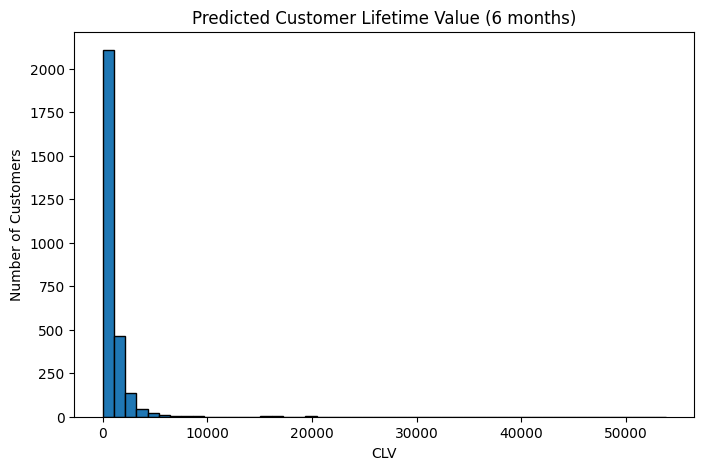

In [60]:

plt.figure(figsize=(8,5))
plt.hist(returning_customers['predicted_clv_6m'], bins=50, edgecolor='k')
plt.title('Predicted Customer Lifetime Value (6 months)')
plt.xlabel('CLV')
plt.ylabel('Number of Customers')
plt.show()


In [61]:
# Top 10 most valuable customers
top_customers = returning_customers.sort_values(by='predicted_clv_6m', ascending=False).head(10)
print(top_customers[['predicted_clv_6m', 'expected_avg_value', 'predicted_purchases_3m']])


            predicted_clv_6m  expected_avg_value  predicted_purchases_3m
CustomerID                                                              
14096.0         53836.119389         2904.990926                9.628091
14911.0         44572.701112          755.720407               30.580424
14646.0         37522.645051         1893.917314               10.273243
14156.0         19735.677428          958.610697               10.674745
13089.0         19518.744916          577.298025               17.530624
18102.0         17186.368231         1562.353738                5.703933
17511.0         16238.235366         1223.447513                6.881908
14088.0         16079.609029         2736.031748                3.048127
12415.0         15912.515631         2028.092375                4.068963
14298.0         15456.375275         1435.633672                5.582711


In [62]:
# add predicted CLV to main data
data = data.merge(
    returning_customers[['predicted_clv_6m']],
    on='CustomerID',
    how='left'
)


In [63]:
data.to_csv('data_merged.csv', sep=',', encoding='utf-8', index=False)

In [64]:
# CLV distribution
fig1 = px.histogram(
    returning_customers,
    x='predicted_clv_6m',
    nbins=50,
    title='📊 Distribution of Predicted Customer Lifetime Value (6 months)',
    color_discrete_sequence=['#2E86AB']
)
fig1.update_layout(xaxis_title='Predicted CLV', yaxis_title='Number of Customers')
fig1.show()

# top 10 Customers by CLV
top_customers = (
    returning_customers.sort_values(by='predicted_clv_6m', ascending=False)
    .head(10)
    .reset_index()
)

fig2 = px.bar(
    top_customers,
    x='CustomerID',
    y='predicted_clv_6m',
    color='expected_avg_value',
    color_continuous_scale='viridis',
    title='💎 Top 10 Customers by Predicted CLV (6 months)',
)
fig2.update_layout(xaxis_title='Customer ID', yaxis_title='Predicted CLV')
fig2.show()

# average CLV by Country (if available)
if 'Country' in data.columns:
    avg_clv_country = data.groupby('Country')['predicted_clv_6m'].mean().reset_index()

    fig3 = px.bar(
        avg_clv_country.sort_values(by='predicted_clv_6m', ascending=False).head(15),
        x='Country',
        y='predicted_clv_6m',
        title='🌍 Average Predicted CLV by Country (Top 15)',
        color='predicted_clv_6m',
        color_continuous_scale='tealrose'
    )
    fig3.update_layout(xaxis_title='Country', yaxis_title='Average CLV')
    fig3.show()
else:
    print("⚠️ 'Country' column not found — skipping country-level CLV plot.")


In [65]:
# Average CLV by Sentiment
if 'Sentiment' in data.columns:
    avg_clv_sentiment = data.groupby('Sentiment')['predicted_clv_6m'].mean().reset_index()

    fig_sentiment = px.bar(
        avg_clv_sentiment.sort_values(by='predicted_clv_6m', ascending=False),
        x='Sentiment',
        y='predicted_clv_6m',
        color='predicted_clv_6m',
        color_continuous_scale='blues',
        title='📈 Average Predicted CLV by Sentiment of Purchased Products'
    )
    fig_sentiment.update_layout(xaxis_title='Sentiment', yaxis_title='Average CLV')
    fig_sentiment.show()
else:
    print("⚠️ 'Sentiment' column not found — skipping sentiment-level CLV plot.")

# Average CLV by Semantic Cluster

if 'ProductClusterSemantic' in data.columns:
    avg_clv_cluster = data.groupby('ProductClusterSemantic')['predicted_clv_6m'].mean().reset_index()

    fig_cluster = px.bar(
        avg_clv_cluster.sort_values(by='predicted_clv_6m', ascending=False).head(20),
        x='ProductClusterSemantic',
        y='predicted_clv_6m',
        color='predicted_clv_6m',
        color_continuous_scale='viridis',
        title='💡 Average Predicted CLV by Semantic Product Cluster (Top 20)'
    )
    fig_cluster.update_layout(xaxis_title='Semantic Cluster', yaxis_title='Average CLV')
    fig_cluster.show()
else:
    print("⚠️ 'ProductClusterSemantic' column not found — skipping semantic cluster-level CLV plot.")


## 📊 CLV Trends Over Time 

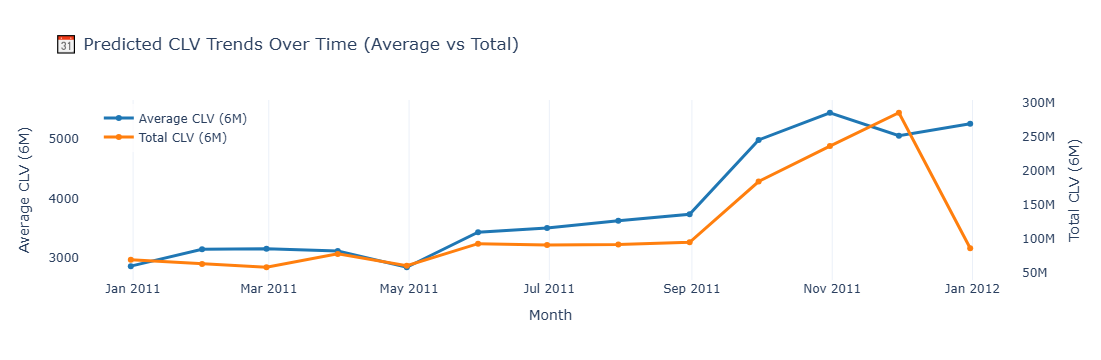

In [72]:
# 📊 CLV Trends Over Time (Plotly Dual View)


if 'InvoiceDate' in data.columns:
    data['InvoiceDate'] = pd.to_datetime(data['InvoiceDate'], errors='coerce')
    data = data.dropna(subset=['InvoiceDate'])

    clv_trend = (
        data.groupby(pd.Grouper(key='InvoiceDate', freq='M'))['predicted_clv_6m']
        .agg(['mean', 'sum'])
        .reset_index()
        .dropna()
        .rename(columns={'mean': 'Average_CLV', 'sum': 'Total_CLV'})
    )

    fig = go.Figure()

    fig.add_trace(go.Scatter(
        x=clv_trend['InvoiceDate'],
        y=clv_trend['Average_CLV'],
        mode='lines+markers',
        name='Average CLV (6M)',
        line=dict(color='#1f77b4', width=3)
    ))

    fig.add_trace(go.Scatter(
        x=clv_trend['InvoiceDate'],
        y=clv_trend['Total_CLV'],
        mode='lines+markers',
        name='Total CLV (6M)',
        line=dict(color='#ff7f0e', width=3),
        yaxis='y2'
    ))
    
    fig.update_layout(
        title='📆 Predicted CLV Trends Over Time (Average vs Total)',
        xaxis=dict(title='Month'),
        yaxis=dict(title='Average CLV (6M)', showgrid=False),
        yaxis2=dict(
            title='Total CLV (6M)',
            overlaying='y',
            side='right',
            showgrid=False
        ),
        legend=dict(x=0.02, y=0.98, bgcolor='rgba(255,255,255,0.7)'),
        template='plotly_white'
    )

    fig.show()
else:
    print("⚠️ 'InvoiceDate' column not found — skipping CLV trend plot.")


### 📊 Remarks on Predicted CLV Trends Over Time (Average vs Total)

- **Overall Trend:**  
  Both *Average CLV (6M)* and *Total CLV (6M)* show a gradual increase over the year 2011, with noticeable acceleration in the second half of the year.

- **Early Period (Jan – May 2011):**  
  CLV values remain relatively stable with minor fluctuations, suggesting consistent customer value and spending behavior during this period.

- **Mid-Year Growth (Jun – Sep 2011):**  
  A steady upward movement in both average and total CLV indicates improving customer engagement or higher retention rates.

- **Peak Performance (Oct – Dec 2011):**  
  The *Average CLV* peaks around November 2011, while *Total CLV* reaches its maximum in December 2011 — likely reflecting a seasonal sales boost or successful marketing campaigns.

- **Decline (Jan 2012):**  
  A sharp drop in *Total CLV* at the beginning of 2012 suggests a post-holiday decrease in customer activity or reduced purchase frequency.

- **Insight:**  
  The divergence between *Average* and *Total CLV* toward the end of the period may indicate that although individual customer value stayed high, the number of active customers decreased.

✅ **Recommendation:**  
  Focus on **retaining customers acquired during the high-CLV months** and analyze **post-holiday churn** to sustain total revenue growth.
